Cargamos nuestro dataset completo, filtramos para ver los nacimientos en la region de Valparaiso en los años 2020-2023


In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargamos el archivo completo
df = pd.read_csv('../data/raw/Serie_Nacimientos_2020_2023.csv', sep=';', low_memory=False)

# 2. Confirmamos que los años ya son correctos (sin hacer filtros innecesarios)
print(f"Años en el dataset: {df['ANO_NAC'].unique()}")

# 3. Filtramos solo la Región de Valparaíso
df_valpo = df[df['GLOSA_REGION_RESIDENCIA'].str.contains('De Valparaíso', na=False, case=False)]

print(f"Total de partos a analizar en Valparaíso: {df_valpo.shape[0]}")

Años en el dataset: [2023 2020 2021 2022]
Total de partos a analizar en Valparaíso: 70037


Eliminamos los valores ignorados, El DEIS anota un 9 cuando la mamá no quiso decir su estado civil o el médico olvidó preguntarle la educación. Además, hay valores atipicos que no tendremos en cuenta. (ej. anotar que un bebé nació a las 10 semanas, lo cual es inviable).


In [10]:
# 1. Eliminar los "Ignorados" (código 9)
# Conservamos solo las filas donde el Nivel y el Estado Civil sean DISTINTOS de 9
df_limpio = df_valpo[(df_valpo['NIVEL_MADRE'] != 9) & (df_valpo['EST_CIV_MADRE'] != 9)].copy()

# 2. Eliminar edades de la madre que digan "no especificado"
df_limpio = df_limpio[df_limpio['GRUPO_ETARIO_MADRE'] != 'no especificado']

# 3. Limpiar errores de digitación en gestación (filtramos para mantener embarazos viables entre 20 y 45 semanas)
df_limpio = df_limpio[(df_limpio['SEMANAS'] >= 20) & (df_limpio['SEMANAS'] <= 45)]

print(f"Registros limpios y listos para analizar: {df_limpio.shape[0]}")

Registros limpios y listos para analizar: 69934


aqui pasamos la variable de nivel de educacion madre a texto, ya que en el excell se representa de manera numerica, lo hacemos para poder mostrar graficos con informacion relevante.


In [11]:
# Mapeamos los números según el diccionario oficial que encontraste
mapa_educacion = {
    1: 'Superior', 
    2: 'Medio (Chilenas)', 
    3: 'Secundario (Extranjeras)', # ¡Nuestro gran hallazgo!
    4: 'Básico/Primario', 
    5: 'Ninguno'
}
df_limpio['NIVEL_DESC'] = df_limpio['NIVEL_MADRE'].map(mapa_educacion)

# Hacemos lo mismo para el Estado Civil
mapa_civil = {1: 'Soltera', 2: 'Casada', 3: 'Otra', 4: 'Otra', 5: 'Otra', 6: 'Conviviente Civil'}
df_limpio['CIVIL_AGRUPADO'] = df_limpio['EST_CIV_MADRE'].map(mapa_civil)

df_limpio[['NIVEL_DESC', 'CIVIL_AGRUPADO']].head()

,NIVEL_DESC,CIVIL_AGRUPADO
21,Medio (Chilenas),Casada
44,Medio (Chilenas),Soltera
49,Medio (Chilenas),Soltera
61,Básico/Primario,Soltera
87,Superior,Soltera


nuestro primer grafico - Semanas de gestacion Vs Educacion -


C:\Users\HP\AppData\Local\Temp\ipykernel_14280\2256517785.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_limpio, x='NIVEL_DESC', y='SEMANAS', order=orden_edu, palette='viridis')


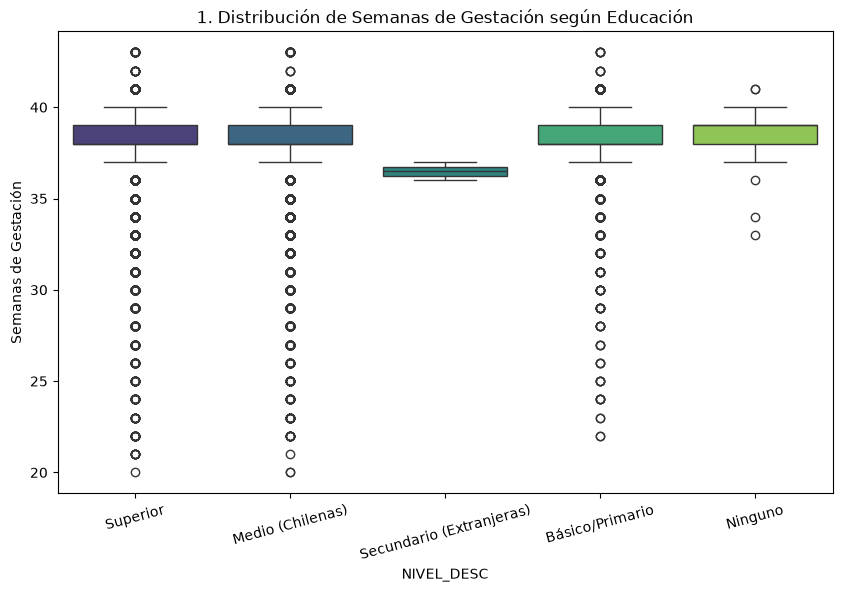

In [12]:
# Gráfico 1: Boxplot de Semanas
plt.figure(figsize=(10, 6))
orden_edu = ['Superior', 'Medio (Chilenas)', 'Secundario (Extranjeras)', 'Básico/Primario', 'Ninguno']

sns.boxplot(data=df_limpio, x='NIVEL_DESC', y='SEMANAS', order=orden_edu, palette='viridis')
plt.title('1. Distribución de Semanas de Gestación según Educación')
plt.xticks(rotation=15)
plt.ylabel('Semanas de Gestación')
plt.show()

**Conclusión del Análisis de Gestación (Y1):**
Al observar la distribución, notamos que la biología humana actúa como un factor estabilizador: la gran mayoría de los partos, independiente del nivel educativo (Superior, Medio o Básico), concentra su mediana de gestación de forma normativa en las 38-39 semanas. Existe una alta presencia de valores atípicos (partos prematuros extremos menores a 30 semanas) en casi todos los estratos.

*Nota sobre la categoría "Secundario":* El diccionario de datos del DEIS indica que esta categoría clasifica a madres extranjeras. Su distribución anómala (mediana en 36-37 semanas, nula dispersión y ausencia de valores atípicos) sugiere fuertemente un bajo volumen de registros (N muy pequeño) bajo este código específico en los recintos de salud de Valparaíso para el periodo 2020-2023, ya que la mayoría de los títulos migrantes tienden a homologarse a educación "Media" o "Superior".

como descubrimos que el tiempo de gestación no era el problema principal, decidimos cambiar nuestro enfoque hacia la nutrición del bebé: el Peso al Nacer. Pero nos topamos con un problema técnico: en el Excel, el peso venía escrito como texto (ej. '< 1500' o '3000-3999'). Como Python no puede sumar ni promediar palabras, transformamos ese texto a números. Creamos una variable nueva llamada BAJO_PESO: le dijimos al código que si el bebé pesaba menos de 2500 gramos le pusiera un 1 (Riesgo), y si pesaba normal le pusiera un 0 (Sano). Con puros unos y ceros, ahora sí podíamos calcular porcentajes matemáticos.

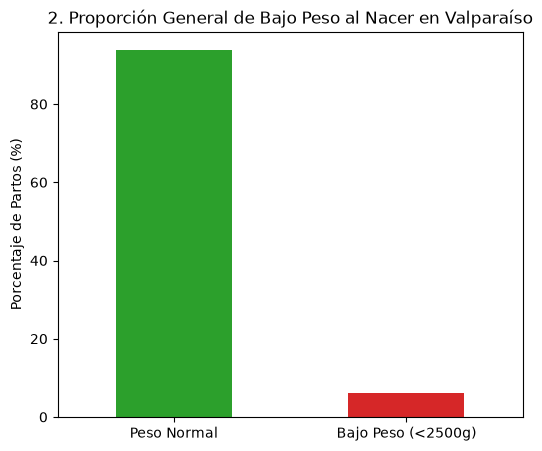

In [13]:
# Transformamos el texto a números (1 = Riesgo, 0 = Sano)
df_limpio['BAJO_PESO'] = df_limpio['RANGO_PESO'].apply(lambda x: 1 if x in ['< 1500', '1500 - 2499'] else 0)

# Gráfico 2: Distribución general de la variable objetivo (Y)
plt.figure(figsize=(6, 5))
conteo_peso = df_limpio['BAJO_PESO'].value_counts(normalize=True) * 100
conteo_peso.index = ['Peso Normal', 'Bajo Peso (<2500g)']

conteo_peso.plot(kind='bar', color=['#2ca02c', '#d62728'])
plt.title('2. Proporción General de Bajo Peso al Nacer en Valparaíso')
plt.ylabel('Porcentaje de Partos (%)')
plt.xticks(rotation=0)
plt.show()

**Definición de la Variable Objetivo (Y2 - Bajo Peso):**
Al descartar las semanas de gestación, el análisis pivota hacia el peso neonatal. A nivel regional, un 6% de los nacimientos presenta bajo peso (< 2500g). Esta visualización establece nuestra línea base. El siguiente paso es descubrir si este 6% se distribuye de manera equitativa en la sociedad o si castiga más a los sectores vulnerables.

Ya con nuestra nueva variable numérica (BAJO_PESO), la comparamos nuevamente con el Nivel Educacional usando un gráfico de barras. Aquí comprobamos nuestra hipótesis: la desigualdad socioeconómica no acorta el embarazo, pero sí desnutre al bebé.

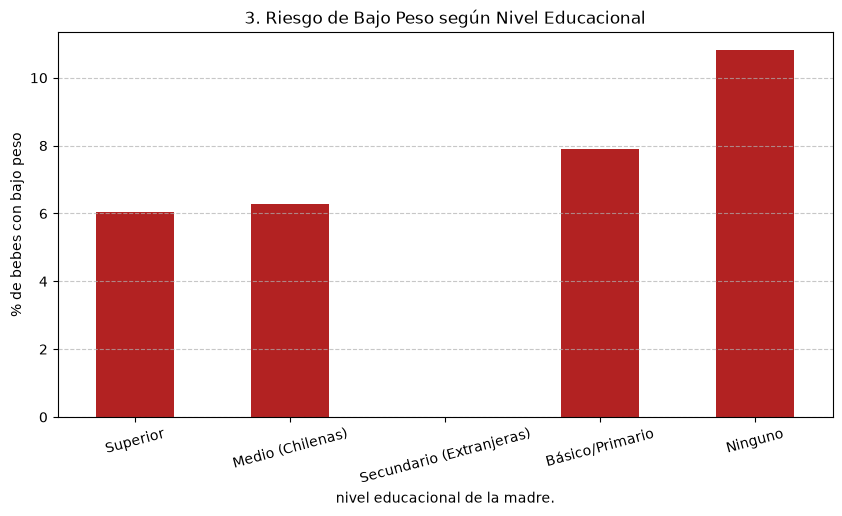

In [16]:
# Gráfico 3: Riesgo porcentual según Educación
plt.figure(figsize=(10, 5))
riesgo_edu = df_limpio.groupby('NIVEL_DESC')['BAJO_PESO'].mean() * 100
riesgo_edu = riesgo_edu.reindex(orden_edu)

riesgo_edu.plot(kind='bar', color='firebrick')
plt.title('3. Riesgo de Bajo Peso según Nivel Educacional')
plt.xlabel('nivel educacional de la madre.')
plt.ylabel('% de bebes con bajo peso')
plt.xticks(rotation=15)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

**Hallazgo Principal: La Brecha Socioeconómica:**
Este gráfico responde directamente a la pregunta del proyecto. El riesgo de bajo peso al nacer tiene una correlación directa con la falta de educación formal. Las madres clasificadas en "Ninguno" alcanzan casi un 11% de incidencia, prácticamente duplicando el riesgo frente al 6% de las madres con educación "Superior". La vulnerabilidad educacional impacta severamente la nutrición y desarrollo fetal. *(Nota: La ausencia de barra en "Secundario" se debe a una tasa de 0% de bajo peso en su reducida muestra).*

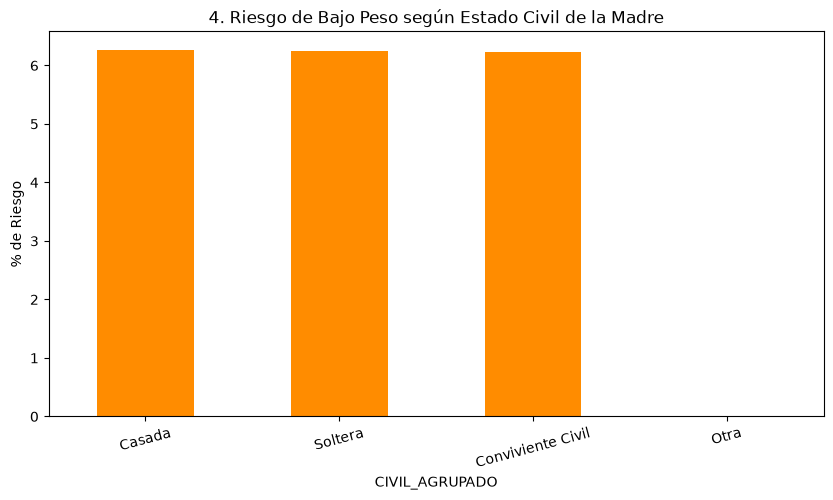

In [18]:
# Gráfico 4: Riesgo porcentual según Estado Civil
plt.figure(figsize=(10, 5))
riesgo_civil = df_limpio.groupby('CIVIL_AGRUPADO')['BAJO_PESO'].mean() * 100

# Ordenamos de mayor a menor riesgo para que se vea mejor
riesgo_civil = riesgo_civil.sort_values(ascending=False)

riesgo_civil.plot(kind='bar', color='darkorange')
plt.title('4. Riesgo de Bajo Peso según Estado Civil de la Madre')
plt.ylabel('% de Riesgo')
plt.xticks(rotation=15)
plt.show()

**Contraste de Variables Explicativas (El Estado Civil no influye):**
para estar seguros de que el problema era educacional y no familiar o economico, hicimos un unevo grafico comparando nuestra variable BAJO_PESO con el Estado civil de la madre (agrupamos a las viudas y separadas en la categoria 'otra' porque eran muy pocas.) 
A diferencia de la variable educacional, la red de apoyo formal (Estado Civil) no genera variaciones en la salud del bebé. Las madres casadas, solteras y convivientes civiles presentan exactamente el mismo nivel de riesgo (cercano al 6.2%). Esto nos permite aislar el problema y concluir que la amenaza para el recién nacido es estrictamente socioeconómica (educación/ingresos), no familiar.

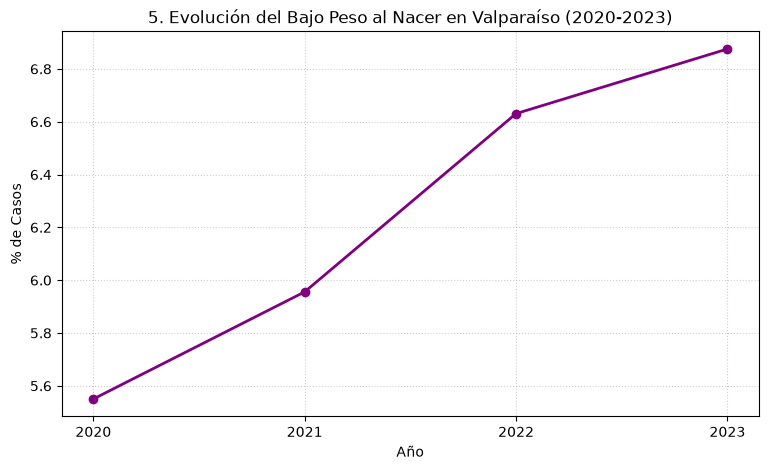

In [19]:
# Gráfico 5: Evolución temporal (Líneas)
plt.figure(figsize=(9, 5))
riesgo_temporal = df_limpio.groupby('ANO_NAC')['BAJO_PESO'].mean() * 100

plt.plot(riesgo_temporal.index, riesgo_temporal.values, marker='o', color='purple', linewidth=2)
plt.title('5. Evolución del Bajo Peso al Nacer en Valparaíso (2020-2023)')
plt.xlabel('Año')
plt.ylabel('% de Casos')
plt.xticks([2020, 2021, 2022, 2023]) # Forzamos a que solo muestre años enteros
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

**Evolución Temporal del Riesgo (Contexto T):**
El análisis del periodo 2020-2023 revela una tendencia al alza ininterrumpida en la tasa general de bajo peso al nacer en Valparaíso. El problema no es estático; se está agravando año a año, lo que justifica la pertinencia y urgencia de este proyecto de análisis de datos para la toma de decisiones en salud pública.